# Model Performance Analysis

This notebook analyzes the performance of models trained with different alpha values and expansion factors across three evaluation datasets: ImageNet-1K, ImageNet-V2, and Blurred ImageNet-1K.

## 1. Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for better-looking plots
sns.set_style("whitegrid")
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load and Explore the Data

In [2]:
# Load the data
df = pd.read_csv('FULL_RESULTS.csv')

print(f"Dataset shape: {df.shape}")
print(f"\nColumns: {list(df.columns)}")
print(f"\nFirst few rows:")
df.head()

Dataset shape: (36, 10)

Columns: ['alpha', 'beta', 'lr', 'expansion', 'imagenet_1k accuracy', 'imagenet_1k ECE', 'imagenet_v2 accuracy', 'imagenet_v2 ECE', 'blurred_imagenet_1k accuracy', 'blurred_imagenet_1k ECE']

First few rows:


,alpha,beta,lr,expansion,imagenet_1k accuracy,imagenet_1k ECE,imagenet_v2 accuracy,imagenet_v2 ECE,blurred_imagenet_1k accuracy,blurred_imagenet_1k ECE
0,-1.0,1.0,0.001,2,0.7540,0.065360,0.0120,0.742724,0.6855,0.084125
1,-1.0,1.0,0.001,4,0.7590,0.075434,0.0125,0.757552,0.6995,0.082115
2,-1.0,1.0,0.001,32,0.6545,0.138408,0.0130,0.705802,0.5680,0.151443
3,0.0,1.0,0.001,2,0.0010,0.005796,0.0010,0.005797,0.0010,0.005807
4,0.0,1.0,0.001,4,0.0010,0.007029,0.0010,0.007028,0.0010,0.007044


In [3]:
# Basic statistics
print("Alpha values:", sorted(df['alpha'].unique()))
print("Expansion factors:", sorted(df['expansion'].unique()))
print("\nDataset info:")
df.info()

Alpha values: [-1.0, 0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
Expansion factors: [2, 4, 32]

Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 10 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alpha                         36 non-null     float64
 1   beta                          36 non-null     float64
 2   lr                            36 non-null     float64
 3   expansion                     36 non-null     int64  
 4   imagenet_1k accuracy          36 non-null     float64
 5   imagenet_1k ECE               36 non-null     float64
 6   imagenet_v2 accuracy          36 non-null     float64
 7   imagenet_v2 ECE               36 non-null     float64
 8   blurred_imagenet_1k accuracy  36 non-null     float64
 9   blurred_imagenet_1k ECE       36 non-null     float64
dtypes: float64(9), int64(1)
memory usage: 2.9 KB


## 3. Data Preprocessing and Grouping

In [4]:
# Separate data by characteristics
df_fixed_alpha = df[df['alpha'] >= 0].copy()  # Fixed alpha values (0 to 1)
df_scheduled = df[df['alpha'] == -1].copy()  # Scheduled alpha
df_baseline = df[df['alpha'] == 1.0].copy()  # Baseline (control)

print(f"Fixed alpha models: {len(df_fixed_alpha)} rows")
print(f"Scheduled alpha models: {len(df_scheduled)} rows")
print(f"Baseline models: {len(df_baseline)} rows")

# Create a label for better visualization
df['alpha_type'] = df['alpha'].apply(lambda x: 'Scheduled' if x == -1 else ('Baseline' if x == 1.0 else 'Fixed'))
df['expansion_label'] = df['expansion'].apply(lambda x: f'Expansion {x}')

Fixed alpha models: 33 rows
Scheduled alpha models: 3 rows
Baseline models: 3 rows


## 4. Accuracy vs Alpha by Expansion Factor

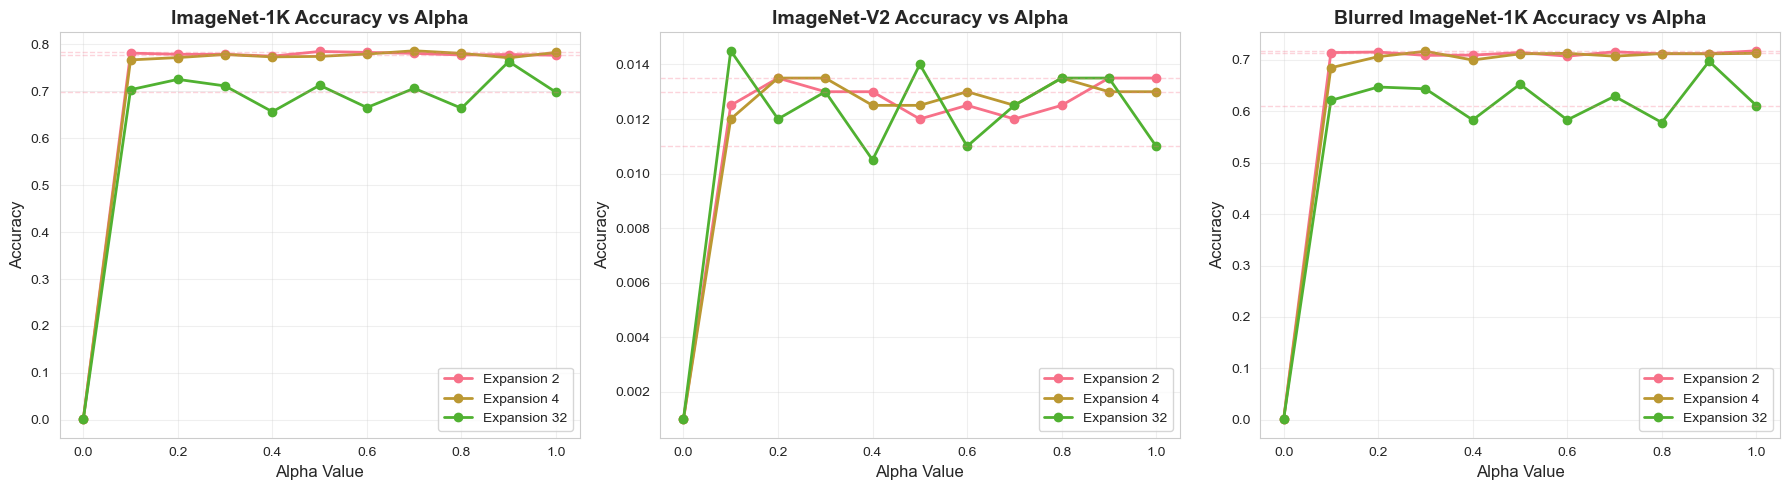

Note: Dashed lines represent baseline (alpha=1.0) performance for each expansion factor


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
datasets = ['imagenet_1k accuracy', 'imagenet_v2 accuracy', 'blurred_imagenet_1k accuracy']
titles = ['ImageNet-1K', 'ImageNet-V2', 'Blurred ImageNet-1K']

for idx, (dataset, title) in enumerate(zip(datasets, titles)):
    ax = axes[idx]
    
    # Plot for each expansion factor
    for exp in sorted(df_fixed_alpha['expansion'].unique()):
        data = df_fixed_alpha[df_fixed_alpha['expansion'] == exp]
        ax.plot(data['alpha'], data[dataset], marker='o', linewidth=2, 
                label=f'Expansion {exp}', markersize=6)
    
    # Add baseline reference lines
    for exp in sorted(df_baseline['expansion'].unique()):
        baseline_acc = df_baseline[df_baseline['expansion'] == exp][dataset].values[0]
        ax.axhline(y=baseline_acc, linestyle='--', alpha=0.3, linewidth=1)
    
    ax.set_xlabel('Alpha Value', fontsize=12)
    ax.set_ylabel('Accuracy', fontsize=12)
    ax.set_title(f'{title} Accuracy vs Alpha', fontsize=14, fontweight='bold')
    ax.legend(loc='best')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Note: Dashed lines represent baseline (alpha=1.0) performance for each expansion factor")

## 5. ECE vs Alpha by Expansion Factor

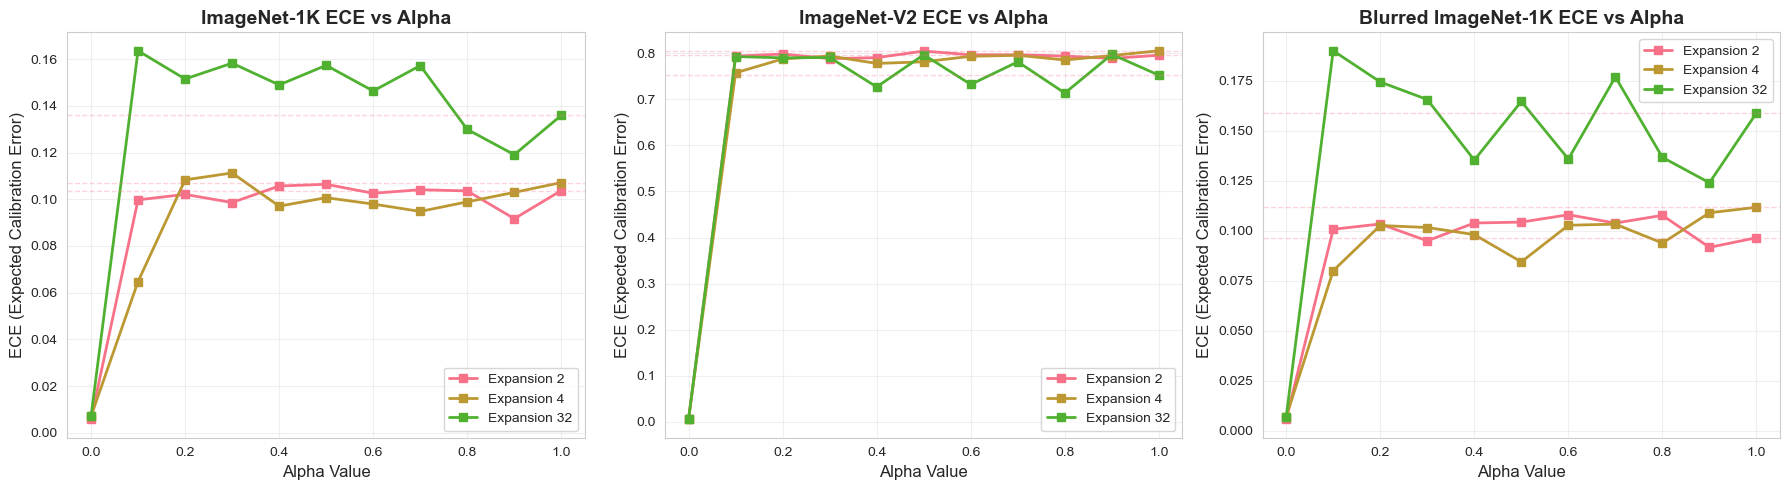

Note: Lower ECE is better. Dashed lines represent baseline (alpha=1.0) ECE for each expansion factor


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ece_datasets = ['imagenet_1k ECE', 'imagenet_v2 ECE', 'blurred_imagenet_1k ECE']
titles = ['ImageNet-1K', 'ImageNet-V2', 'Blurred ImageNet-1K']

for idx, (dataset, title) in enumerate(zip(ece_datasets, titles)):
    ax = axes[idx]
    
    # Plot for each expansion factor
    for exp in sorted(df_fixed_alpha['expansion'].unique()):
        data = df_fixed_alpha[df_fixed_alpha['expansion'] == exp]
        ax.plot(data['alpha'], data[dataset], marker='s', linewidth=2, 
                label=f'Expansion {exp}', markersize=6)
    
    # Add baseline reference lines
    for exp in sorted(df_baseline['expansion'].unique()):
        baseline_ece = df_baseline[df_baseline['expansion'] == exp][dataset].values[0]
        ax.axhline(y=baseline_ece, linestyle='--', alpha=0.3, linewidth=1)
    
    ax.set_xlabel('Alpha Value', fontsize=12)
    ax.set_ylabel('ECE (Expected Calibration Error)', fontsize=12)
    ax.set_title(f'{title} ECE vs Alpha', fontsize=14, fontweight='bold')
    ax.legend(loc='best')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Note: Lower ECE is better. Dashed lines represent baseline (alpha=1.0) ECE for each expansion factor")

## 6. Accuracy Comparison Across Datasets

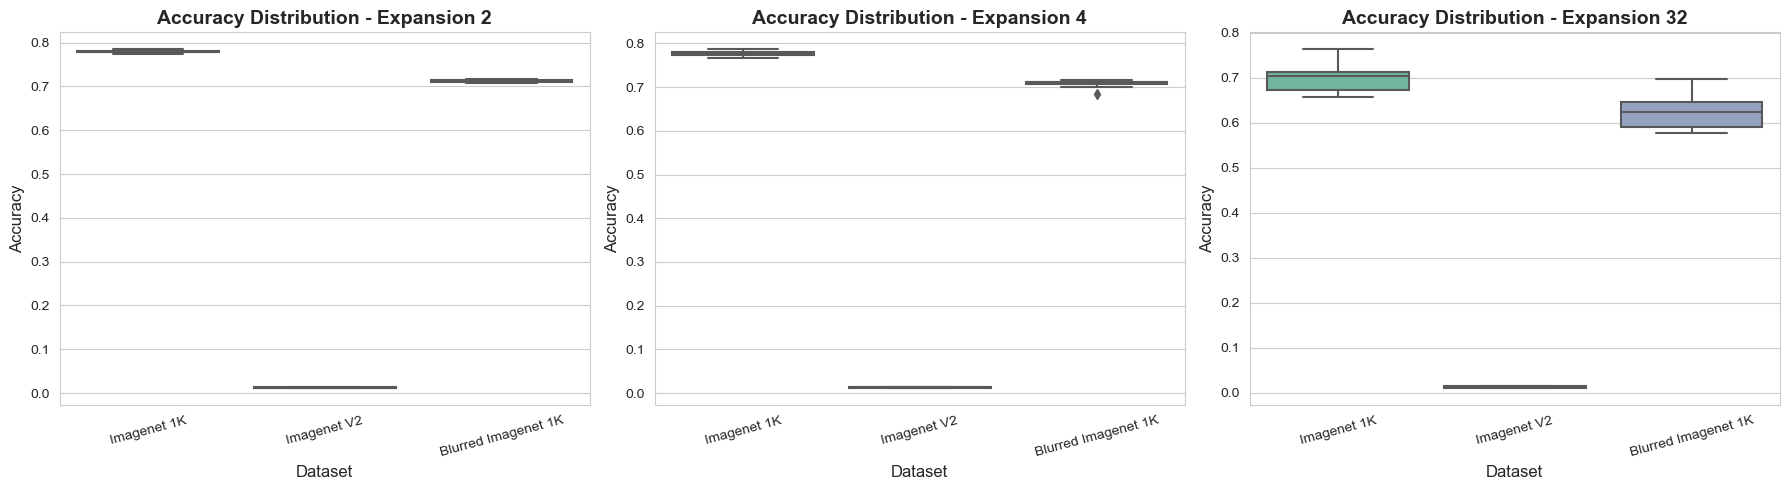

In [7]:
# Reshape data for grouped comparison (excluding alpha=0 which has very low accuracy)
df_plot = df_fixed_alpha[df_fixed_alpha['alpha'] > 0].copy()

# Melt the dataframe for easier plotting
acc_melted = df_plot.melt(
    id_vars=['alpha', 'expansion'], 
    value_vars=['imagenet_1k accuracy', 'imagenet_v2 accuracy', 'blurred_imagenet_1k accuracy'],
    var_name='Dataset', 
    value_name='Accuracy'
)
acc_melted['Dataset'] = acc_melted['Dataset'].str.replace(' accuracy', '').str.replace('_', ' ').str.title()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, exp in enumerate(sorted(df_plot['expansion'].unique())):
    ax = axes[idx]
    data = acc_melted[acc_melted['expansion'] == exp]
    
    sns.boxplot(data=data, x='Dataset', y='Accuracy', ax=ax, palette='Set2')
    ax.set_title(f'Accuracy Distribution - Expansion {exp}', fontsize=14, fontweight='bold')
    ax.set_xlabel('Dataset', fontsize=12)
    ax.set_ylabel('Accuracy', fontsize=12)
    ax.tick_params(axis='x', rotation=15)
    
plt.tight_layout()
plt.show()

## 7. ECE Comparison Across Datasets

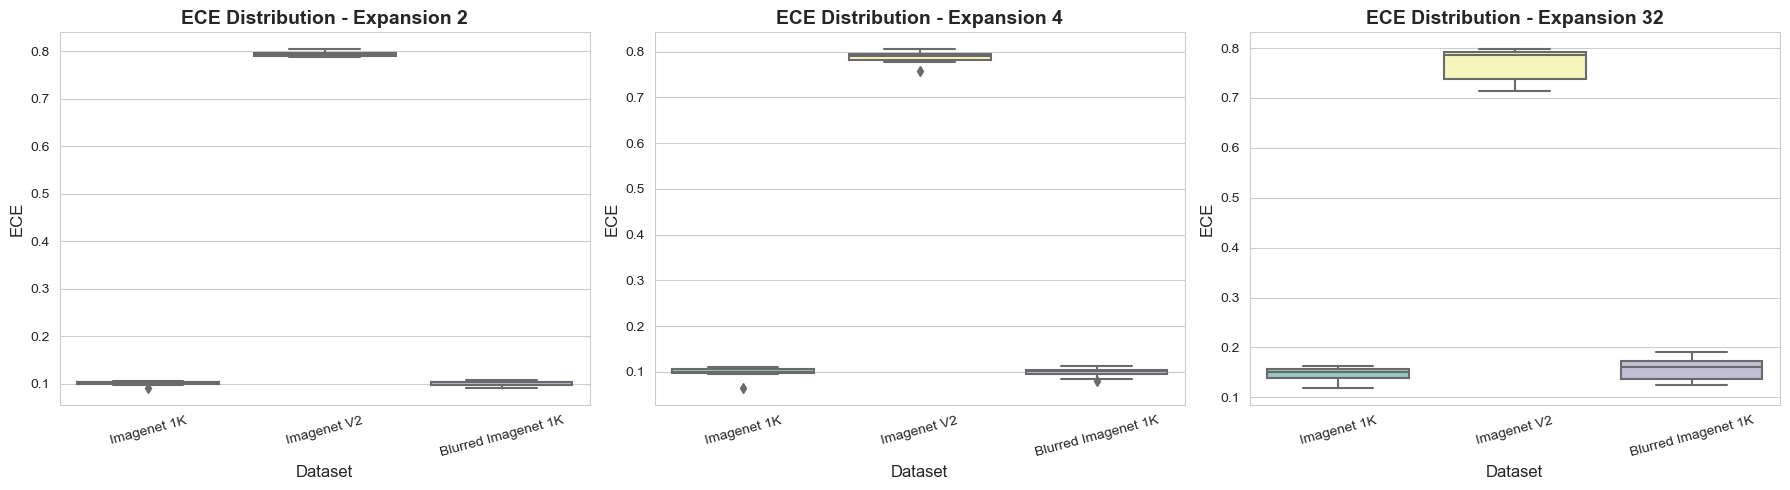

In [8]:
# Melt ECE data for comparison
ece_melted = df_plot.melt(
    id_vars=['alpha', 'expansion'], 
    value_vars=['imagenet_1k ECE', 'imagenet_v2 ECE', 'blurred_imagenet_1k ECE'],
    var_name='Dataset', 
    value_name='ECE'
)
ece_melted['Dataset'] = ece_melted['Dataset'].str.replace(' ECE', '').str.replace('_', ' ').str.title()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, exp in enumerate(sorted(df_plot['expansion'].unique())):
    ax = axes[idx]
    data = ece_melted[ece_melted['expansion'] == exp]
    
    sns.boxplot(data=data, x='Dataset', y='ECE', ax=ax, palette='Set3')
    ax.set_title(f'ECE Distribution - Expansion {exp}', fontsize=14, fontweight='bold')
    ax.set_xlabel('Dataset', fontsize=12)
    ax.set_ylabel('ECE', fontsize=12)
    ax.tick_params(axis='x', rotation=15)
    
plt.tight_layout()
plt.show()

## 8. Accuracy vs ECE Trade-off Analysis

/var/folders/l8/tp2sn6_j48ddt15xflhpdr5r0000gn/T/ipykernel_83459/954299411.py:30: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


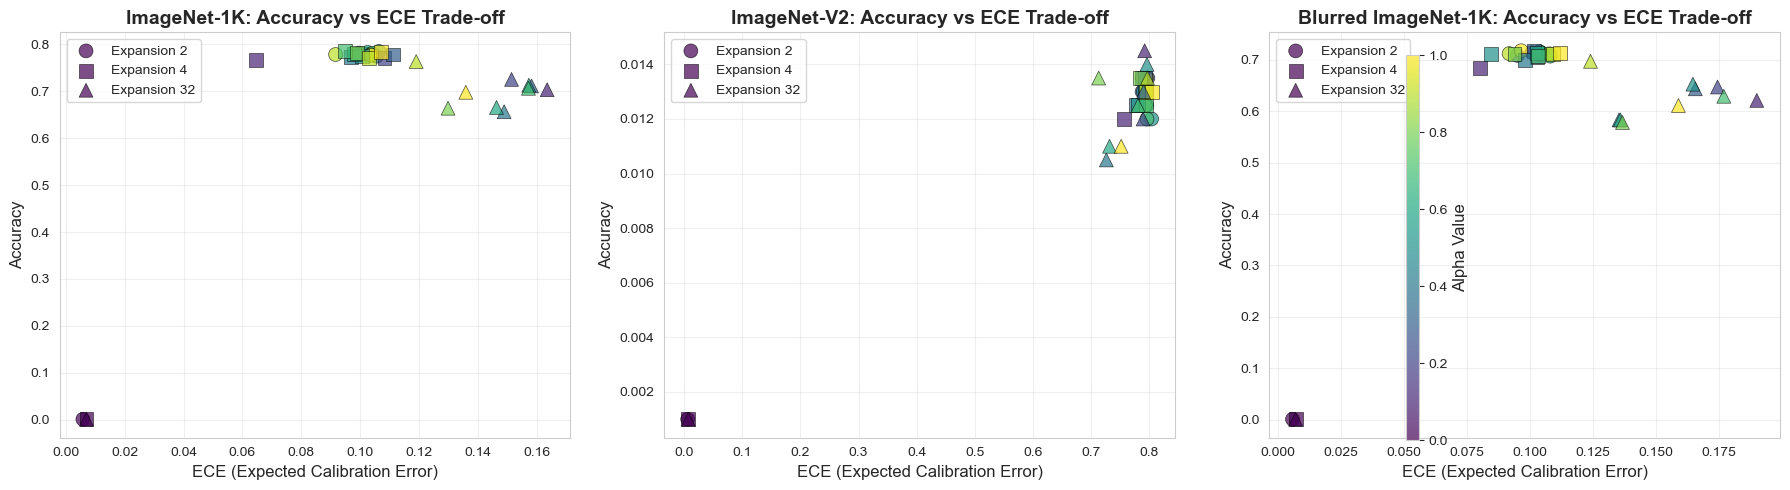

Ideal models are in the top-left corner (high accuracy, low ECE)


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
dataset_pairs = [
    ('imagenet_1k accuracy', 'imagenet_1k ECE', 'ImageNet-1K'),
    ('imagenet_v2 accuracy', 'imagenet_v2 ECE', 'ImageNet-V2'),
    ('blurred_imagenet_1k accuracy', 'blurred_imagenet_1k ECE', 'Blurred ImageNet-1K')
]

for idx, (acc_col, ece_col, title) in enumerate(dataset_pairs):
    ax = axes[idx]
    
    # Plot for each expansion factor with different markers
    markers = ['o', 's', '^']
    for exp, marker in zip(sorted(df_fixed_alpha['expansion'].unique()), markers):
        data = df_fixed_alpha[df_fixed_alpha['expansion'] == exp]
        scatter = ax.scatter(data[ece_col], data[acc_col], 
                           c=data['alpha'], cmap='viridis', 
                           marker=marker, s=100, alpha=0.7, 
                           label=f'Expansion {exp}', edgecolors='black', linewidth=0.5)
    
    ax.set_xlabel('ECE (Expected Calibration Error)', fontsize=12)
    ax.set_ylabel('Accuracy', fontsize=12)
    ax.set_title(f'{title}: Accuracy vs ECE Trade-off', fontsize=14, fontweight='bold')
    ax.legend(loc='best')
    ax.grid(True, alpha=0.3)

# Add colorbar for alpha values
cbar = plt.colorbar(scatter, ax=axes, orientation='vertical', pad=0.02, aspect=30)
cbar.set_label('Alpha Value', fontsize=12)

plt.tight_layout()
plt.show()

print("Ideal models are in the top-left corner (high accuracy, low ECE)")

## 9. Heatmaps for Parameter Relationships

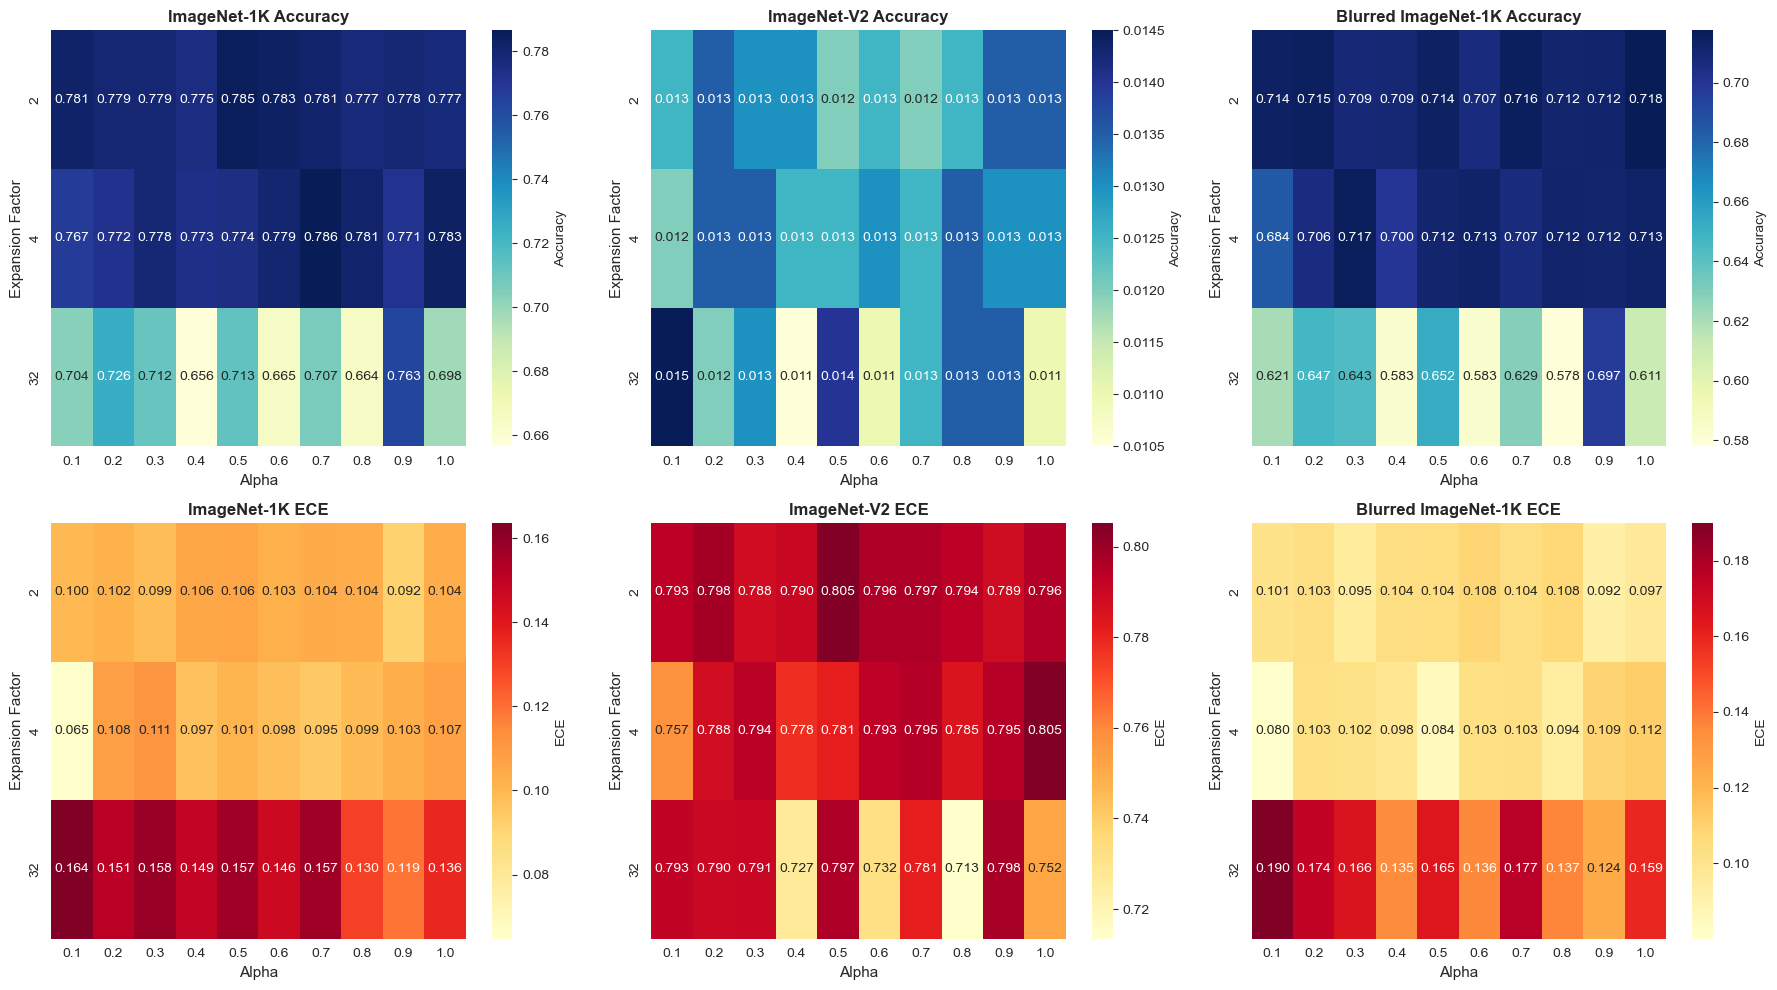

In [11]:
# Create pivot tables for heatmaps (excluding alpha=0 and alpha=-1)
df_heatmap = df_fixed_alpha[(df_fixed_alpha['alpha'] > 0)].copy()

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Accuracy heatmaps
for idx, (dataset, title) in enumerate(zip(datasets, titles)):
    ax = axes[0, idx]
    pivot = df_heatmap.pivot_table(values=dataset, index='expansion', columns='alpha')
    sns.heatmap(pivot, annot=True, fmt='.3f', cmap='YlGnBu', ax=ax, cbar_kws={'label': 'Accuracy'})
    ax.set_title(f'{title} Accuracy', fontsize=12, fontweight='bold')
    ax.set_xlabel('Alpha', fontsize=11)
    ax.set_ylabel('Expansion Factor', fontsize=11)

# ECE heatmaps
for idx, (dataset, title) in enumerate(zip(ece_datasets, titles)):
    ax = axes[1, idx]
    pivot = df_heatmap.pivot_table(values=dataset, index='expansion', columns='alpha')
    sns.heatmap(pivot, annot=True, fmt='.3f', cmap='YlOrRd', ax=ax, cbar_kws={'label': 'ECE'})
    ax.set_title(f'{title} ECE', fontsize=12, fontweight='bold')
    ax.set_xlabel('Alpha', fontsize=11)
    ax.set_ylabel('Expansion Factor', fontsize=11)

plt.tight_layout()
plt.show()

## 10. Performance Relative to Baseline

In [12]:
# Calculate relative performance to baseline (alpha=1.0)
df_relative = df_fixed_alpha[df_fixed_alpha['alpha'] < 1.0].copy()

for exp in sorted(df_relative['expansion'].unique()):
    baseline_row = df_baseline[df_baseline['expansion'] == exp].iloc[0]
    
    for dataset in datasets:
        col_name = f'{dataset}_rel'
        df_relative.loc[df_relative['expansion'] == exp, col_name] = \
            ((df_relative.loc[df_relative['expansion'] == exp, dataset] - baseline_row[dataset]) / baseline_row[dataset]) * 100
    
    for dataset in ece_datasets:
        col_name = f'{dataset}_rel'
        df_relative.loc[df_relative['expansion'] == exp, col_name] = \
            ((df_relative.loc[df_relative['expansion'] == exp, dataset] - baseline_row[dataset]) / baseline_row[dataset]) * 100

print("Calculated relative performance to baseline (alpha=1.0)")

Calculated relative performance to baseline (alpha=1.0)


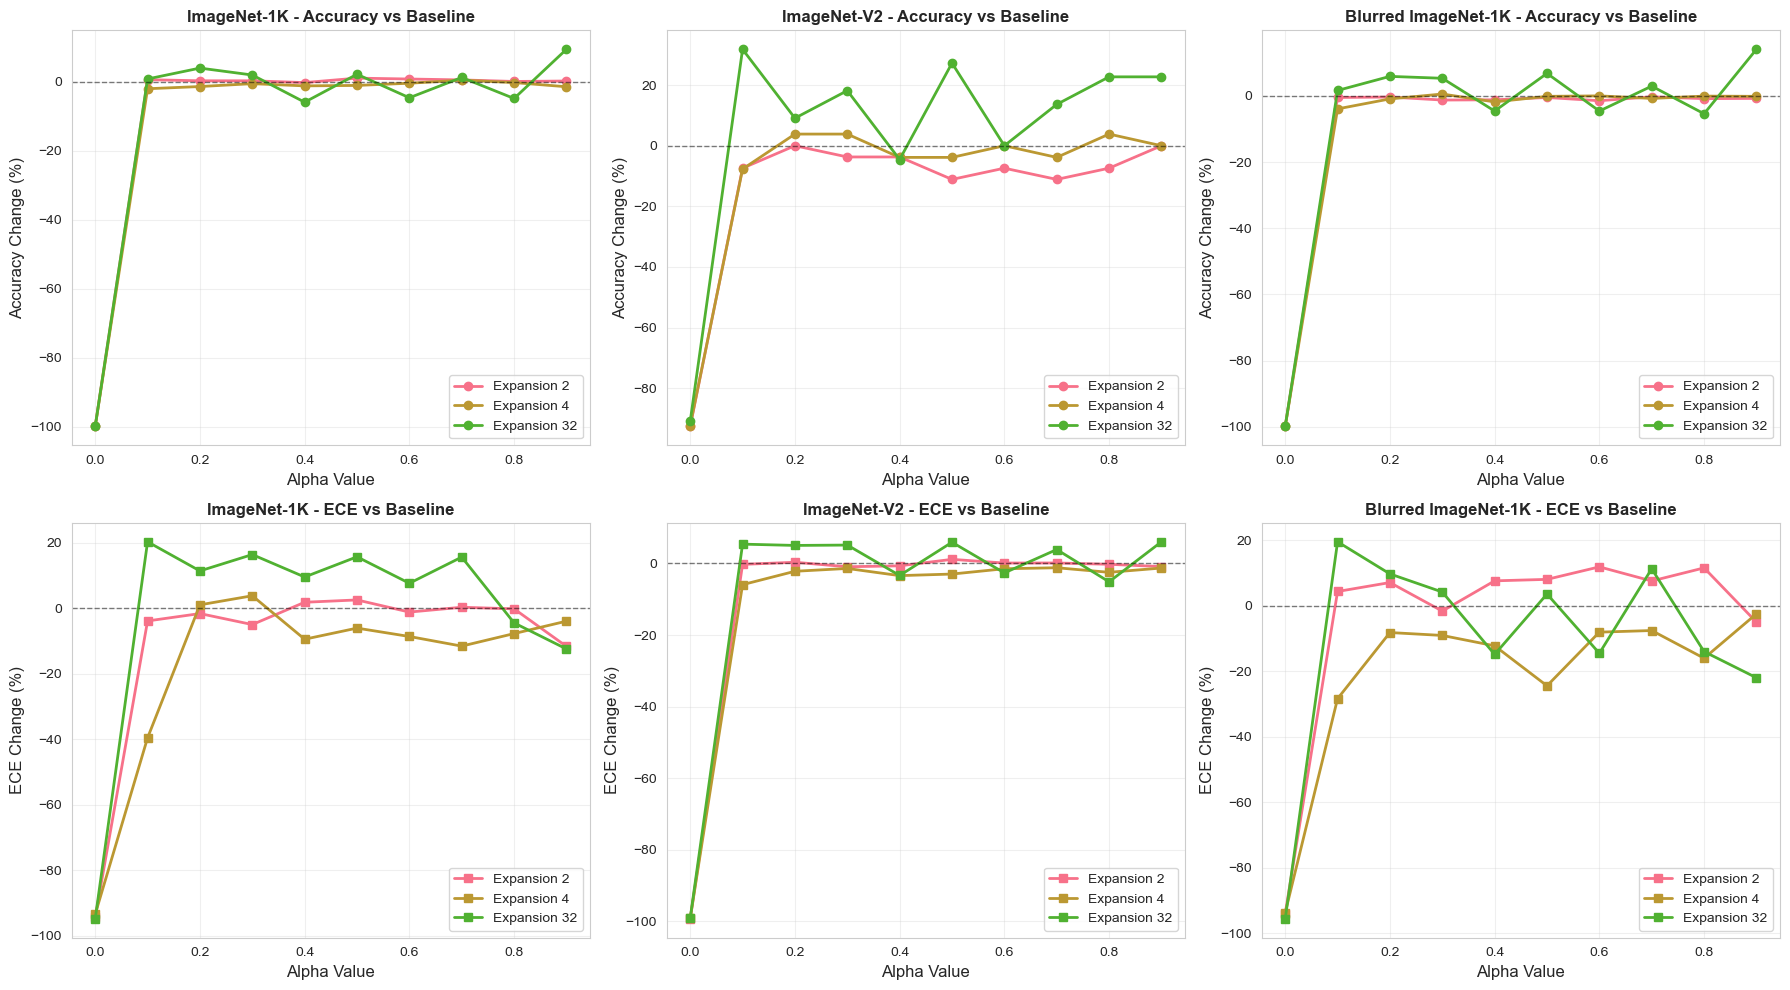

Positive values indicate improvement over baseline for accuracy
Negative values indicate improvement over baseline for ECE (lower is better)


In [13]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Relative accuracy plots
for idx, (dataset, title) in enumerate(zip(datasets, titles)):
    ax = axes[0, idx]
    col_name = f'{dataset}_rel'
    
    for exp in sorted(df_relative['expansion'].unique()):
        data = df_relative[df_relative['expansion'] == exp]
        ax.plot(data['alpha'], data[col_name], marker='o', linewidth=2, 
                label=f'Expansion {exp}', markersize=6)
    
    ax.axhline(y=0, color='black', linestyle='--', linewidth=1, alpha=0.5)
    ax.set_xlabel('Alpha Value', fontsize=12)
    ax.set_ylabel('Accuracy Change (%)', fontsize=12)
    ax.set_title(f'{title} - Accuracy vs Baseline', fontsize=12, fontweight='bold')
    ax.legend(loc='best')
    ax.grid(True, alpha=0.3)

# Relative ECE plots
for idx, (dataset, title) in enumerate(zip(ece_datasets, titles)):
    ax = axes[1, idx]
    col_name = f'{dataset}_rel'
    
    for exp in sorted(df_relative['expansion'].unique()):
        data = df_relative[df_relative['expansion'] == exp]
        ax.plot(data['alpha'], data[col_name], marker='s', linewidth=2, 
                label=f'Expansion {exp}', markersize=6)
    
    ax.axhline(y=0, color='black', linestyle='--', linewidth=1, alpha=0.5)
    ax.set_xlabel('Alpha Value', fontsize=12)
    ax.set_ylabel('ECE Change (%)', fontsize=12)
    ax.set_title(f'{title} - ECE vs Baseline', fontsize=12, fontweight='bold')
    ax.legend(loc='best')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Positive values indicate improvement over baseline for accuracy")
print("Negative values indicate improvement over baseline for ECE (lower is better)")

## Performance Relative to Scheduled Alpha (alpha=-1)

## 11. Summary Statistics and Best Configurations

In [22]:
# Find best configurations for each metric, separated by expansion factor
print("=" * 80)
print("BEST CONFIGURATIONS BY METRIC (SEPARATED BY EXPANSION FACTOR)")
print("=" * 80)

# Include all models (fixed alpha and scheduled)
df_all_models = df[df['alpha'] != 0].copy()  # Exclude only alpha=0

for exp in sorted(df_all_models['expansion'].unique()):
    print(f"\n{'=' * 80}")
    print(f"EXPANSION FACTOR {exp}")
    print('=' * 80)
    
    df_exp = df_all_models[df_all_models['expansion'] == exp].copy()
    baseline_exp = df_baseline[df_baseline['expansion'] == exp].iloc[0]
    
    for dataset, title in zip(datasets, titles):
        print(f"\n{title} - Top 2 Highest Accuracy:")
        top_indices = df_exp.nlargest(2, dataset).index
        for rank, idx in enumerate(top_indices, 1):
            best_row = df_exp.loc[idx]
            alpha_label = "Scheduled" if best_row['alpha'] == -1 else f"{best_row['alpha']:.1f}"
            print(f"  #{rank}: Alpha: {alpha_label}, Accuracy: {best_row[dataset]:.4f}")
        
        # Show baseline performance for reference
        print(f"  Reference - Baseline (alpha=1.0): {baseline_exp[dataset]:.4f}")
    
    print("\n" + "-" * 80)
    
    for dataset, title in zip(ece_datasets, titles):
        print(f"\n{title} - Top 2 Lowest ECE:")
        top_indices = df_exp.nsmallest(2, dataset).index
        for rank, idx in enumerate(top_indices, 1):
            best_row = df_exp.loc[idx]
            alpha_label = "Scheduled" if best_row['alpha'] == -1 else f"{best_row['alpha']:.1f}"
            print(f"  #{rank}: Alpha: {alpha_label}, ECE: {best_row[dataset]:.4f}")
        
        # Show baseline performance for reference
        print(f"  Reference - Baseline (alpha=1.0): {baseline_exp[dataset]:.4f}")

print("\n" + "=" * 80)

BEST CONFIGURATIONS BY METRIC (SEPARATED BY EXPANSION FACTOR)

EXPANSION FACTOR 2

ImageNet-1K - Top 2 Highest Accuracy:
  #1: Alpha: 0.5, Accuracy: 0.7850
  #2: Alpha: 0.6, Accuracy: 0.7830
  Reference - Baseline (alpha=1.0): 0.7770

ImageNet-V2 - Top 2 Highest Accuracy:
  #1: Alpha: 0.2, Accuracy: 0.0135
  #2: Alpha: 0.9, Accuracy: 0.0135
  Reference - Baseline (alpha=1.0): 0.0135

Blurred ImageNet-1K - Top 2 Highest Accuracy:
  #1: Alpha: 1.0, Accuracy: 0.7175
  #2: Alpha: 0.7, Accuracy: 0.7155
  Reference - Baseline (alpha=1.0): 0.7175

--------------------------------------------------------------------------------

ImageNet-1K - Top 2 Lowest ECE:
  #1: Alpha: Scheduled, ECE: 0.0654
  #2: Alpha: 0.9, ECE: 0.0917
  Reference - Baseline (alpha=1.0): 0.1038

ImageNet-V2 - Top 2 Lowest ECE:
  #1: Alpha: Scheduled, ECE: 0.7427
  #2: Alpha: 0.3, ECE: 0.7882
  Reference - Baseline (alpha=1.0): 0.7956

Blurred ImageNet-1K - Top 2 Lowest ECE:
  #1: Alpha: Scheduled, ECE: 0.0841
  #2: Alpha

## Models That Outperform Baseline Across All Metrics

In [17]:
# Compare scheduled vs fixed alpha performance
print("\n" + "=" * 80)
print("SCHEDULED ALPHA (-1) vs BASELINE (1.0) COMPARISON")
print("=" * 80)

for exp in sorted(df['expansion'].unique()):
    print(f"\nExpansion Factor {exp}:")
    scheduled = df_scheduled[df_scheduled['expansion'] == exp].iloc[0]
    baseline = df_baseline[df_baseline['expansion'] == exp].iloc[0]
    
    for dataset, title in zip(datasets, titles):
        acc_diff = (scheduled[dataset] - baseline[dataset]) * 100
        print(f"  {title} Accuracy: Scheduled={scheduled[dataset]:.4f}, Baseline={baseline[dataset]:.4f}, Diff={acc_diff:+.2f}%")
    
    for dataset, title in zip(ece_datasets, titles):
        ece_diff = (scheduled[dataset] - baseline[dataset]) / baseline[dataset] * 100
        print(f"  {title} ECE: Scheduled={scheduled[dataset]:.4f}, Baseline={baseline[dataset]:.4f}, Diff={ece_diff:+.2f}%")

print("\n" + "=" * 80)


SCHEDULED ALPHA (-1) vs BASELINE (1.0) COMPARISON

Expansion Factor 2:
  ImageNet-1K Accuracy: Scheduled=0.7540, Baseline=0.7770, Diff=-2.30%
  ImageNet-V2 Accuracy: Scheduled=0.0120, Baseline=0.0135, Diff=-0.15%
  Blurred ImageNet-1K Accuracy: Scheduled=0.6855, Baseline=0.7175, Diff=-3.20%
  ImageNet-1K ECE: Scheduled=0.0654, Baseline=0.1038, Diff=-37.00%
  ImageNet-V2 ECE: Scheduled=0.7427, Baseline=0.7956, Diff=-6.65%
  Blurred ImageNet-1K ECE: Scheduled=0.0841, Baseline=0.0965, Diff=-12.85%

Expansion Factor 4:
  ImageNet-1K Accuracy: Scheduled=0.7590, Baseline=0.7830, Diff=-2.40%
  ImageNet-V2 Accuracy: Scheduled=0.0125, Baseline=0.0130, Diff=-0.05%
  Blurred ImageNet-1K Accuracy: Scheduled=0.6995, Baseline=0.7125, Diff=-1.30%
  ImageNet-1K ECE: Scheduled=0.0754, Baseline=0.1072, Diff=-29.61%
  ImageNet-V2 ECE: Scheduled=0.7576, Baseline=0.8052, Diff=-5.92%
  Blurred ImageNet-1K ECE: Scheduled=0.0821, Baseline=0.1117, Diff=-26.52%

Expansion Factor 32:
  ImageNet-1K Accuracy: Sch

In [18]:
# Calculate relative performance to scheduled alpha (alpha=-1)
df_relative_scheduled = df_fixed_alpha[df_fixed_alpha['alpha'] >= 0].copy()

for exp in sorted(df_relative_scheduled['expansion'].unique()):
    scheduled_row = df_scheduled[df_scheduled['expansion'] == exp].iloc[0]
    
    for dataset in datasets:
        col_name = f'{dataset}_rel_sched'
        df_relative_scheduled.loc[df_relative_scheduled['expansion'] == exp, col_name] = \
            ((df_relative_scheduled.loc[df_relative_scheduled['expansion'] == exp, dataset] - scheduled_row[dataset]) / scheduled_row[dataset]) * 100
    
    for dataset in ece_datasets:
        col_name = f'{dataset}_rel_sched'
        df_relative_scheduled.loc[df_relative_scheduled['expansion'] == exp, col_name] = \
            ((df_relative_scheduled.loc[df_relative_scheduled['expansion'] == exp, dataset] - scheduled_row[dataset]) / scheduled_row[dataset]) * 100

print("Calculated relative performance to scheduled alpha (alpha=-1)")

Calculated relative performance to scheduled alpha (alpha=-1)


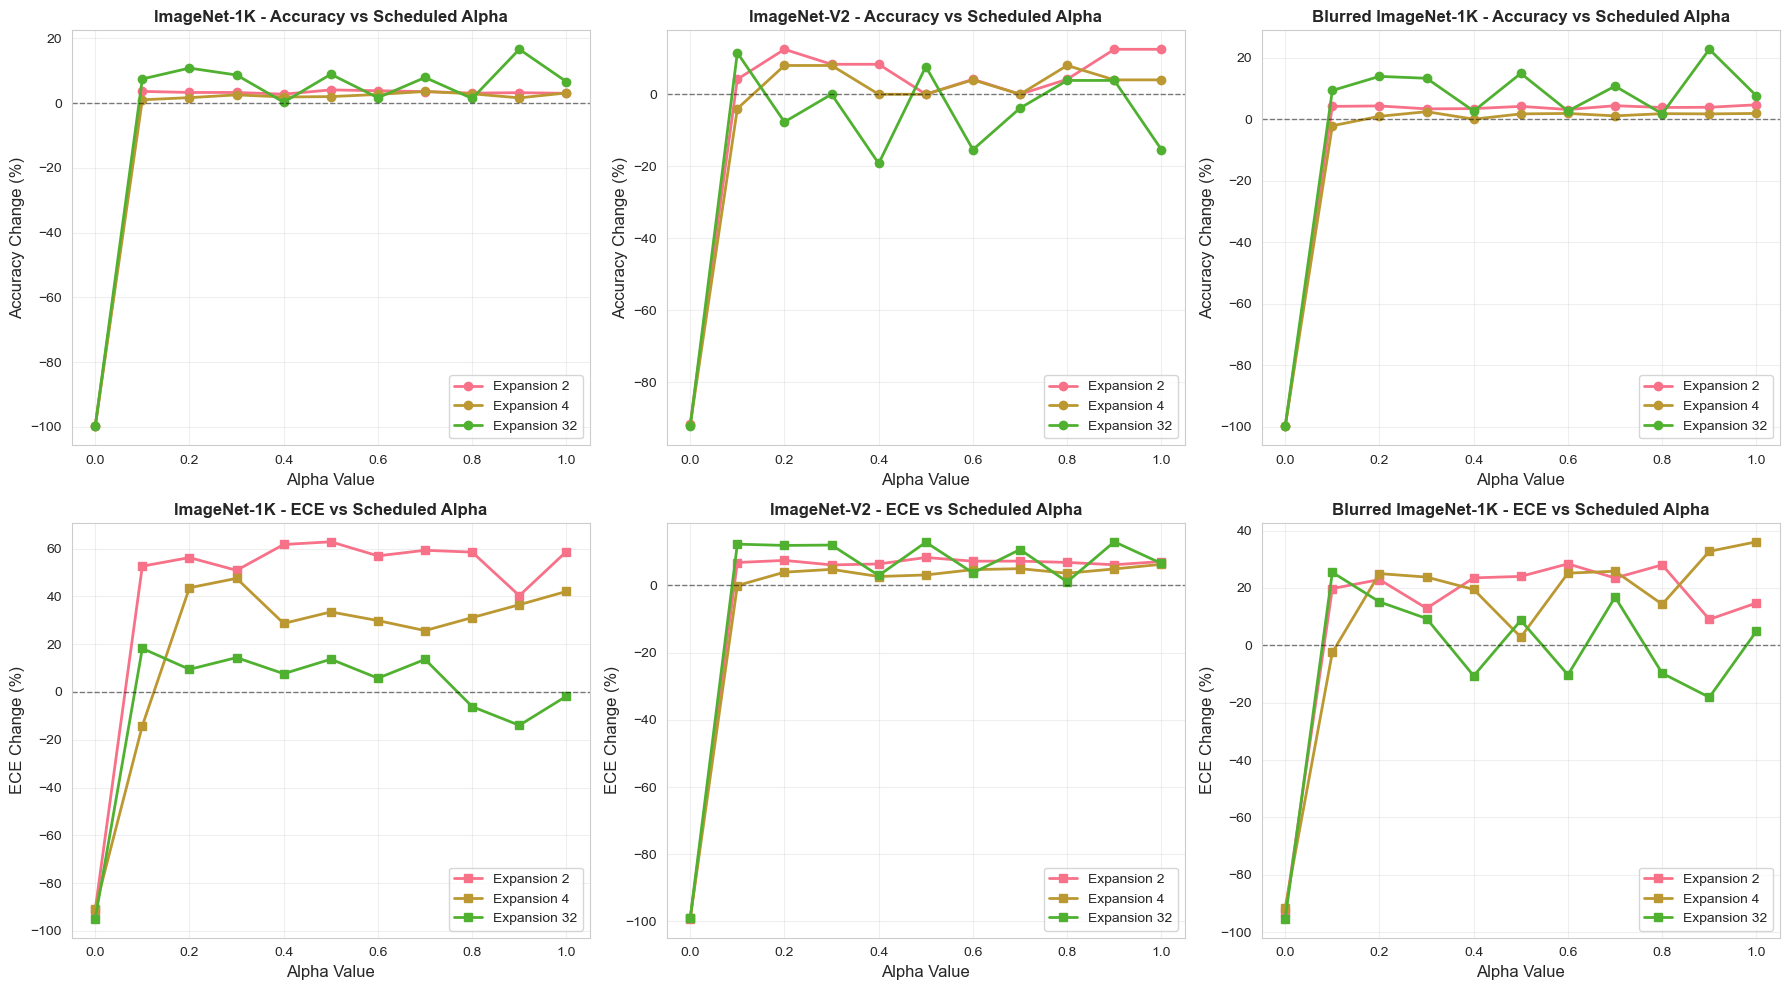

Positive values indicate improvement over scheduled alpha for accuracy
Negative values indicate improvement over scheduled alpha for ECE (lower is better)


In [19]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Relative accuracy plots
for idx, (dataset, title) in enumerate(zip(datasets, titles)):
    ax = axes[0, idx]
    col_name = f'{dataset}_rel_sched'
    
    for exp in sorted(df_relative_scheduled['expansion'].unique()):
        data = df_relative_scheduled[df_relative_scheduled['expansion'] == exp]
        ax.plot(data['alpha'], data[col_name], marker='o', linewidth=2, 
                label=f'Expansion {exp}', markersize=6)
    
    ax.axhline(y=0, color='black', linestyle='--', linewidth=1, alpha=0.5)
    ax.set_xlabel('Alpha Value', fontsize=12)
    ax.set_ylabel('Accuracy Change (%)', fontsize=12)
    ax.set_title(f'{title} - Accuracy vs Scheduled Alpha', fontsize=12, fontweight='bold')
    ax.legend(loc='best')
    ax.grid(True, alpha=0.3)

# Relative ECE plots
for idx, (dataset, title) in enumerate(zip(ece_datasets, titles)):
    ax = axes[1, idx]
    col_name = f'{dataset}_rel_sched'
    
    for exp in sorted(df_relative_scheduled['expansion'].unique()):
        data = df_relative_scheduled[df_relative_scheduled['expansion'] == exp]
        ax.plot(data['alpha'], data[col_name], marker='s', linewidth=2, 
                label=f'Expansion {exp}', markersize=6)
    
    ax.axhline(y=0, color='black', linestyle='--', linewidth=1, alpha=0.5)
    ax.set_xlabel('Alpha Value', fontsize=12)
    ax.set_ylabel('ECE Change (%)', fontsize=12)
    ax.set_title(f'{title} - ECE vs Scheduled Alpha', fontsize=12, fontweight='bold')
    ax.legend(loc='best')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Positive values indicate improvement over scheduled alpha for accuracy")
print("Negative values indicate improvement over scheduled alpha for ECE (lower is better)")

In [24]:
# Find models that beat baseline in ALL accuracy OR ALL ECE metrics
print("=" * 80)
print("MODELS THAT OUTPERFORM BASELINE (ALPHA=1.0)")
print("In All Accuracy Metrics OR All ECE Metrics")
print("=" * 80)

# For each expansion factor, find models that beat baseline
all_winners = []

for exp in sorted(df_all_models['expansion'].unique()):
    print(f"\n{'=' * 80}")
    print(f"EXPANSION FACTOR {exp}")
    print('=' * 80)
    
    df_exp = df_all_models[df_all_models['expansion'] == exp].copy()
    baseline_exp = df_baseline[df_baseline['expansion'] == exp].iloc[0]
    
    # Find models that beat baseline in all accuracy OR all ECE metrics
    winners = []
    for idx, row in df_exp.iterrows():
        if row['alpha'] == 1.0:  # Skip baseline itself
            continue
        
        # Check if this model beats baseline in ALL accuracy metrics
        beats_all_accuracy = True
        for dataset in datasets:
            if row[dataset] <= baseline_exp[dataset]:
                beats_all_accuracy = False
                break
        
        # Check if this model beats baseline in ALL ECE metrics (lower is better)
        beats_all_ece = True
        for dataset in ece_datasets:
            if row[dataset] >= baseline_exp[dataset]:
                beats_all_ece = False
                break
        
        # Model qualifies if it beats baseline in all accuracy OR all ECE
        if beats_all_accuracy or beats_all_ece:
            winners.append({
                'row': row,
                'beats_accuracy': beats_all_accuracy,
                'beats_ece': beats_all_ece
            })
    
    if len(winners) == 0:
        print("\nNo models beat the baseline in all accuracy metrics OR all ECE metrics for this expansion factor.")
    else:
        print(f"\nFound {len(winners)} model(s) that beat baseline:\n")
        
        for i, winner_info in enumerate(winners, 1):
            winner = winner_info['row']
            alpha_label = "Scheduled" if winner['alpha'] == -1 else f"{winner['alpha']:.1f}"
            
            # Indicate what the model beats baseline in
            criteria = []
            if winner_info['beats_accuracy']:
                criteria.append("All Accuracy Metrics")
            if winner_info['beats_ece']:
                criteria.append("All ECE Metrics")
            
            print(f"Model #{i}: Alpha = {alpha_label} (Beats: {' AND '.join(criteria)})")
            print("-" * 40)
            
            # Accuracy metrics
            for dataset, title in zip(datasets, titles):
                acc_change = ((winner[dataset] - baseline_exp[dataset]) / baseline_exp[dataset]) * 100
                beats_marker = "✓" if winner[dataset] > baseline_exp[dataset] else "✗"
                print(f"  {beats_marker} {title} Accuracy: {winner[dataset]:.4f} (Baseline: {baseline_exp[dataset]:.4f}, Change: {acc_change:+.2f}%)")
            
            # ECE metrics
            for dataset, title in zip(ece_datasets, titles):
                ece_change = ((winner[dataset] - baseline_exp[dataset]) / baseline_exp[dataset]) * 100
                beats_marker = "✓" if winner[dataset] < baseline_exp[dataset] else "✗"
                print(f"  {beats_marker} {title} ECE: {winner[dataset]:.4f} (Baseline: {baseline_exp[dataset]:.4f}, Change: {ece_change:+.2f}%)")
            
            print()
            
            # Store for summary
            all_winners.append({
                'expansion': exp,
                'alpha': winner['alpha'],
                'alpha_label': alpha_label,
                'beats_accuracy': winner_info['beats_accuracy'],
                'beats_ece': winner_info['beats_ece']
            })

# Overall summary
print("\n" + "=" * 80)
print("SUMMARY")
print("=" * 80)
print(f"\nTotal models that beat baseline: {len(all_winners)}")

# Count by category
beats_both = sum(1 for w in all_winners if w['beats_accuracy'] and w['beats_ece'])
beats_accuracy_only = sum(1 for w in all_winners if w['beats_accuracy'] and not w['beats_ece'])
beats_ece_only = sum(1 for w in all_winners if w['beats_ece'] and not w['beats_accuracy'])

print(f"  - Beat baseline in ALL accuracy AND ALL ECE metrics: {beats_both}")
print(f"  - Beat baseline in ALL accuracy metrics only: {beats_accuracy_only}")
print(f"  - Beat baseline in ALL ECE metrics only: {beats_ece_only}")

if all_winners:
    print("\nBy expansion factor:")
    for exp in sorted(df_all_models['expansion'].unique()):
        exp_winners = [w for w in all_winners if w['expansion'] == exp]
        count = len(exp_winners)
        print(f"  Expansion {exp}: {count} model(s)")
        models = [w['alpha_label'] for w in exp_winners]
        if models:
            print(f"    Alpha values: {', '.join(models)}")

print("\n" + "=" * 80)

MODELS THAT OUTPERFORM BASELINE (ALPHA=1.0)
In All Accuracy Metrics OR All ECE Metrics

EXPANSION FACTOR 2

Found 3 model(s) that beat baseline:

Model #1: Alpha = Scheduled (Beats: All ECE Metrics)
----------------------------------------
  ✗ ImageNet-1K Accuracy: 0.7540 (Baseline: 0.7770, Change: -2.96%)
  ✗ ImageNet-V2 Accuracy: 0.0120 (Baseline: 0.0135, Change: -11.11%)
  ✗ Blurred ImageNet-1K Accuracy: 0.6855 (Baseline: 0.7175, Change: -4.46%)
  ✓ ImageNet-1K ECE: 0.0654 (Baseline: 0.1038, Change: -37.00%)
  ✓ ImageNet-V2 ECE: 0.7427 (Baseline: 0.7956, Change: -6.65%)
  ✓ Blurred ImageNet-1K ECE: 0.0841 (Baseline: 0.0965, Change: -12.85%)

Model #2: Alpha = 0.3 (Beats: All ECE Metrics)
----------------------------------------
  ✓ ImageNet-1K Accuracy: 0.7790 (Baseline: 0.7770, Change: +0.26%)
  ✗ ImageNet-V2 Accuracy: 0.0130 (Baseline: 0.0135, Change: -3.70%)
  ✗ Blurred ImageNet-1K Accuracy: 0.7085 (Baseline: 0.7175, Change: -1.25%)
  ✓ ImageNet-1K ECE: 0.0986 (Baseline: 0.1038, 

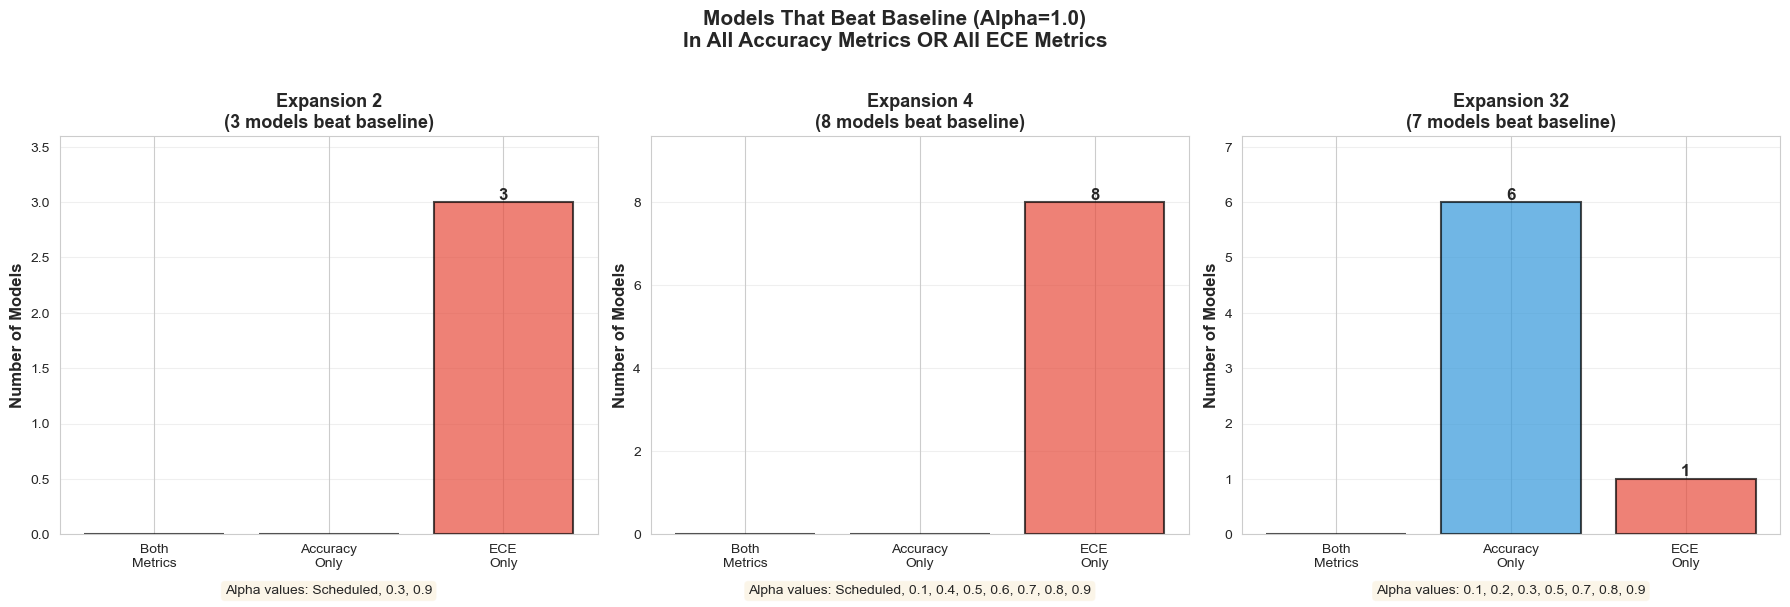

In [25]:
# Visualize models that beat baseline in all accuracy OR all ECE metrics
if all_winners:
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    
    for idx, exp in enumerate(sorted(df_all_models['expansion'].unique())):
        ax = axes[idx]
        
        # Get winners for this expansion factor
        exp_winners = [w for w in all_winners if w['expansion'] == exp]
        
        if exp_winners:
            # Prepare data for visualization
            winner_alphas = [w['alpha'] for w in exp_winners]
            winner_labels = [w['alpha_label'] for w in exp_winners]
            
            # Count how many criteria each model beats
            beats_both_count = sum(1 for w in exp_winners if w['beats_accuracy'] and w['beats_ece'])
            beats_acc_only = sum(1 for w in exp_winners if w['beats_accuracy'] and not w['beats_ece'])
            beats_ece_only = sum(1 for w in exp_winners if w['beats_ece'] and not w['beats_accuracy'])
            
            # Create stacked bar chart
            categories = ['Both\nMetrics', 'Accuracy\nOnly', 'ECE\nOnly']
            counts = [beats_both_count, beats_acc_only, beats_ece_only]
            colors = ['#2ecc71', '#3498db', '#e74c3c']
            
            bars = ax.bar(categories, counts, color=colors, alpha=0.7, edgecolor='black', linewidth=1.5)
            
            # Add count labels on bars
            for bar, count in zip(bars, counts):
                if count > 0:
                    height = bar.get_height()
                    ax.text(bar.get_x() + bar.get_width()/2., height,
                           f'{int(count)}',
                           ha='center', va='bottom', fontweight='bold', fontsize=12)
            
            ax.set_ylabel('Number of Models', fontsize=12, fontweight='bold')
            ax.set_title(f'Expansion {exp}\n({len(exp_winners)} models beat baseline)', 
                        fontsize=13, fontweight='bold')
            ax.set_ylim(0, max(counts) * 1.2 if max(counts) > 0 else 1)
            ax.grid(True, alpha=0.3, axis='y')
            
            # Add model details as text below
            text_y = -0.15
            ax.text(0.5, text_y, f'Alpha values: {", ".join(winner_labels)}',
                   transform=ax.transAxes, ha='center', fontsize=10,
                   bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.3))
        else:
            ax.text(0.5, 0.5, 'No models\nbeat baseline',
                   transform=ax.transAxes, ha='center', va='center',
                   fontsize=14, fontweight='bold', color='gray')
            ax.set_title(f'Expansion {exp}', fontsize=13, fontweight='bold')
            ax.set_ylabel('Number of Models', fontsize=12, fontweight='bold')
            ax.set_xticks([])
    
    plt.suptitle('Models That Beat Baseline (Alpha=1.0)\nIn All Accuracy Metrics OR All ECE Metrics',
                fontsize=15, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()
else:
    print("No models found that beat baseline - skipping visualization.")

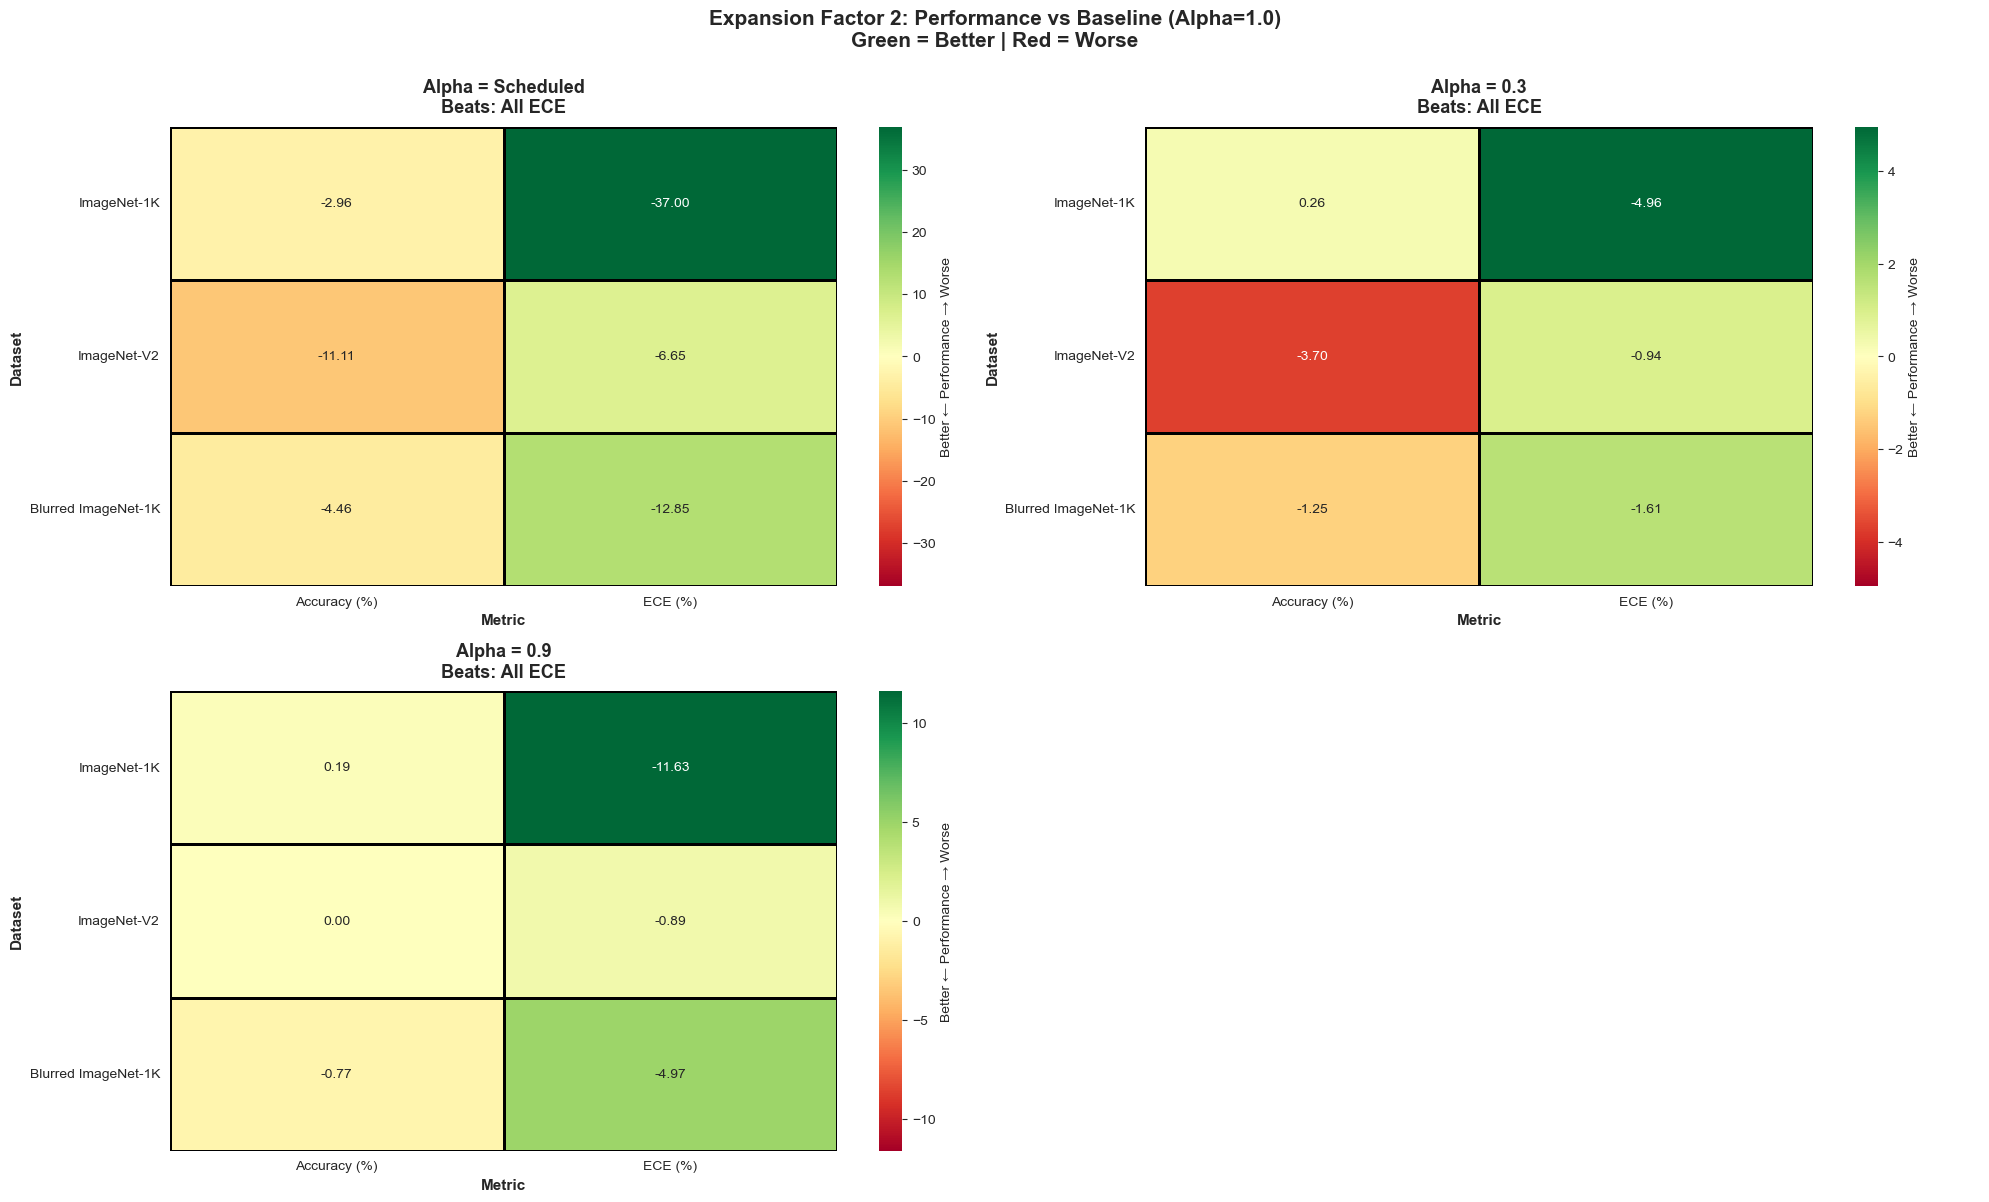

Note: For Accuracy, positive % = improvement. For ECE, negative % = improvement (lower is better).



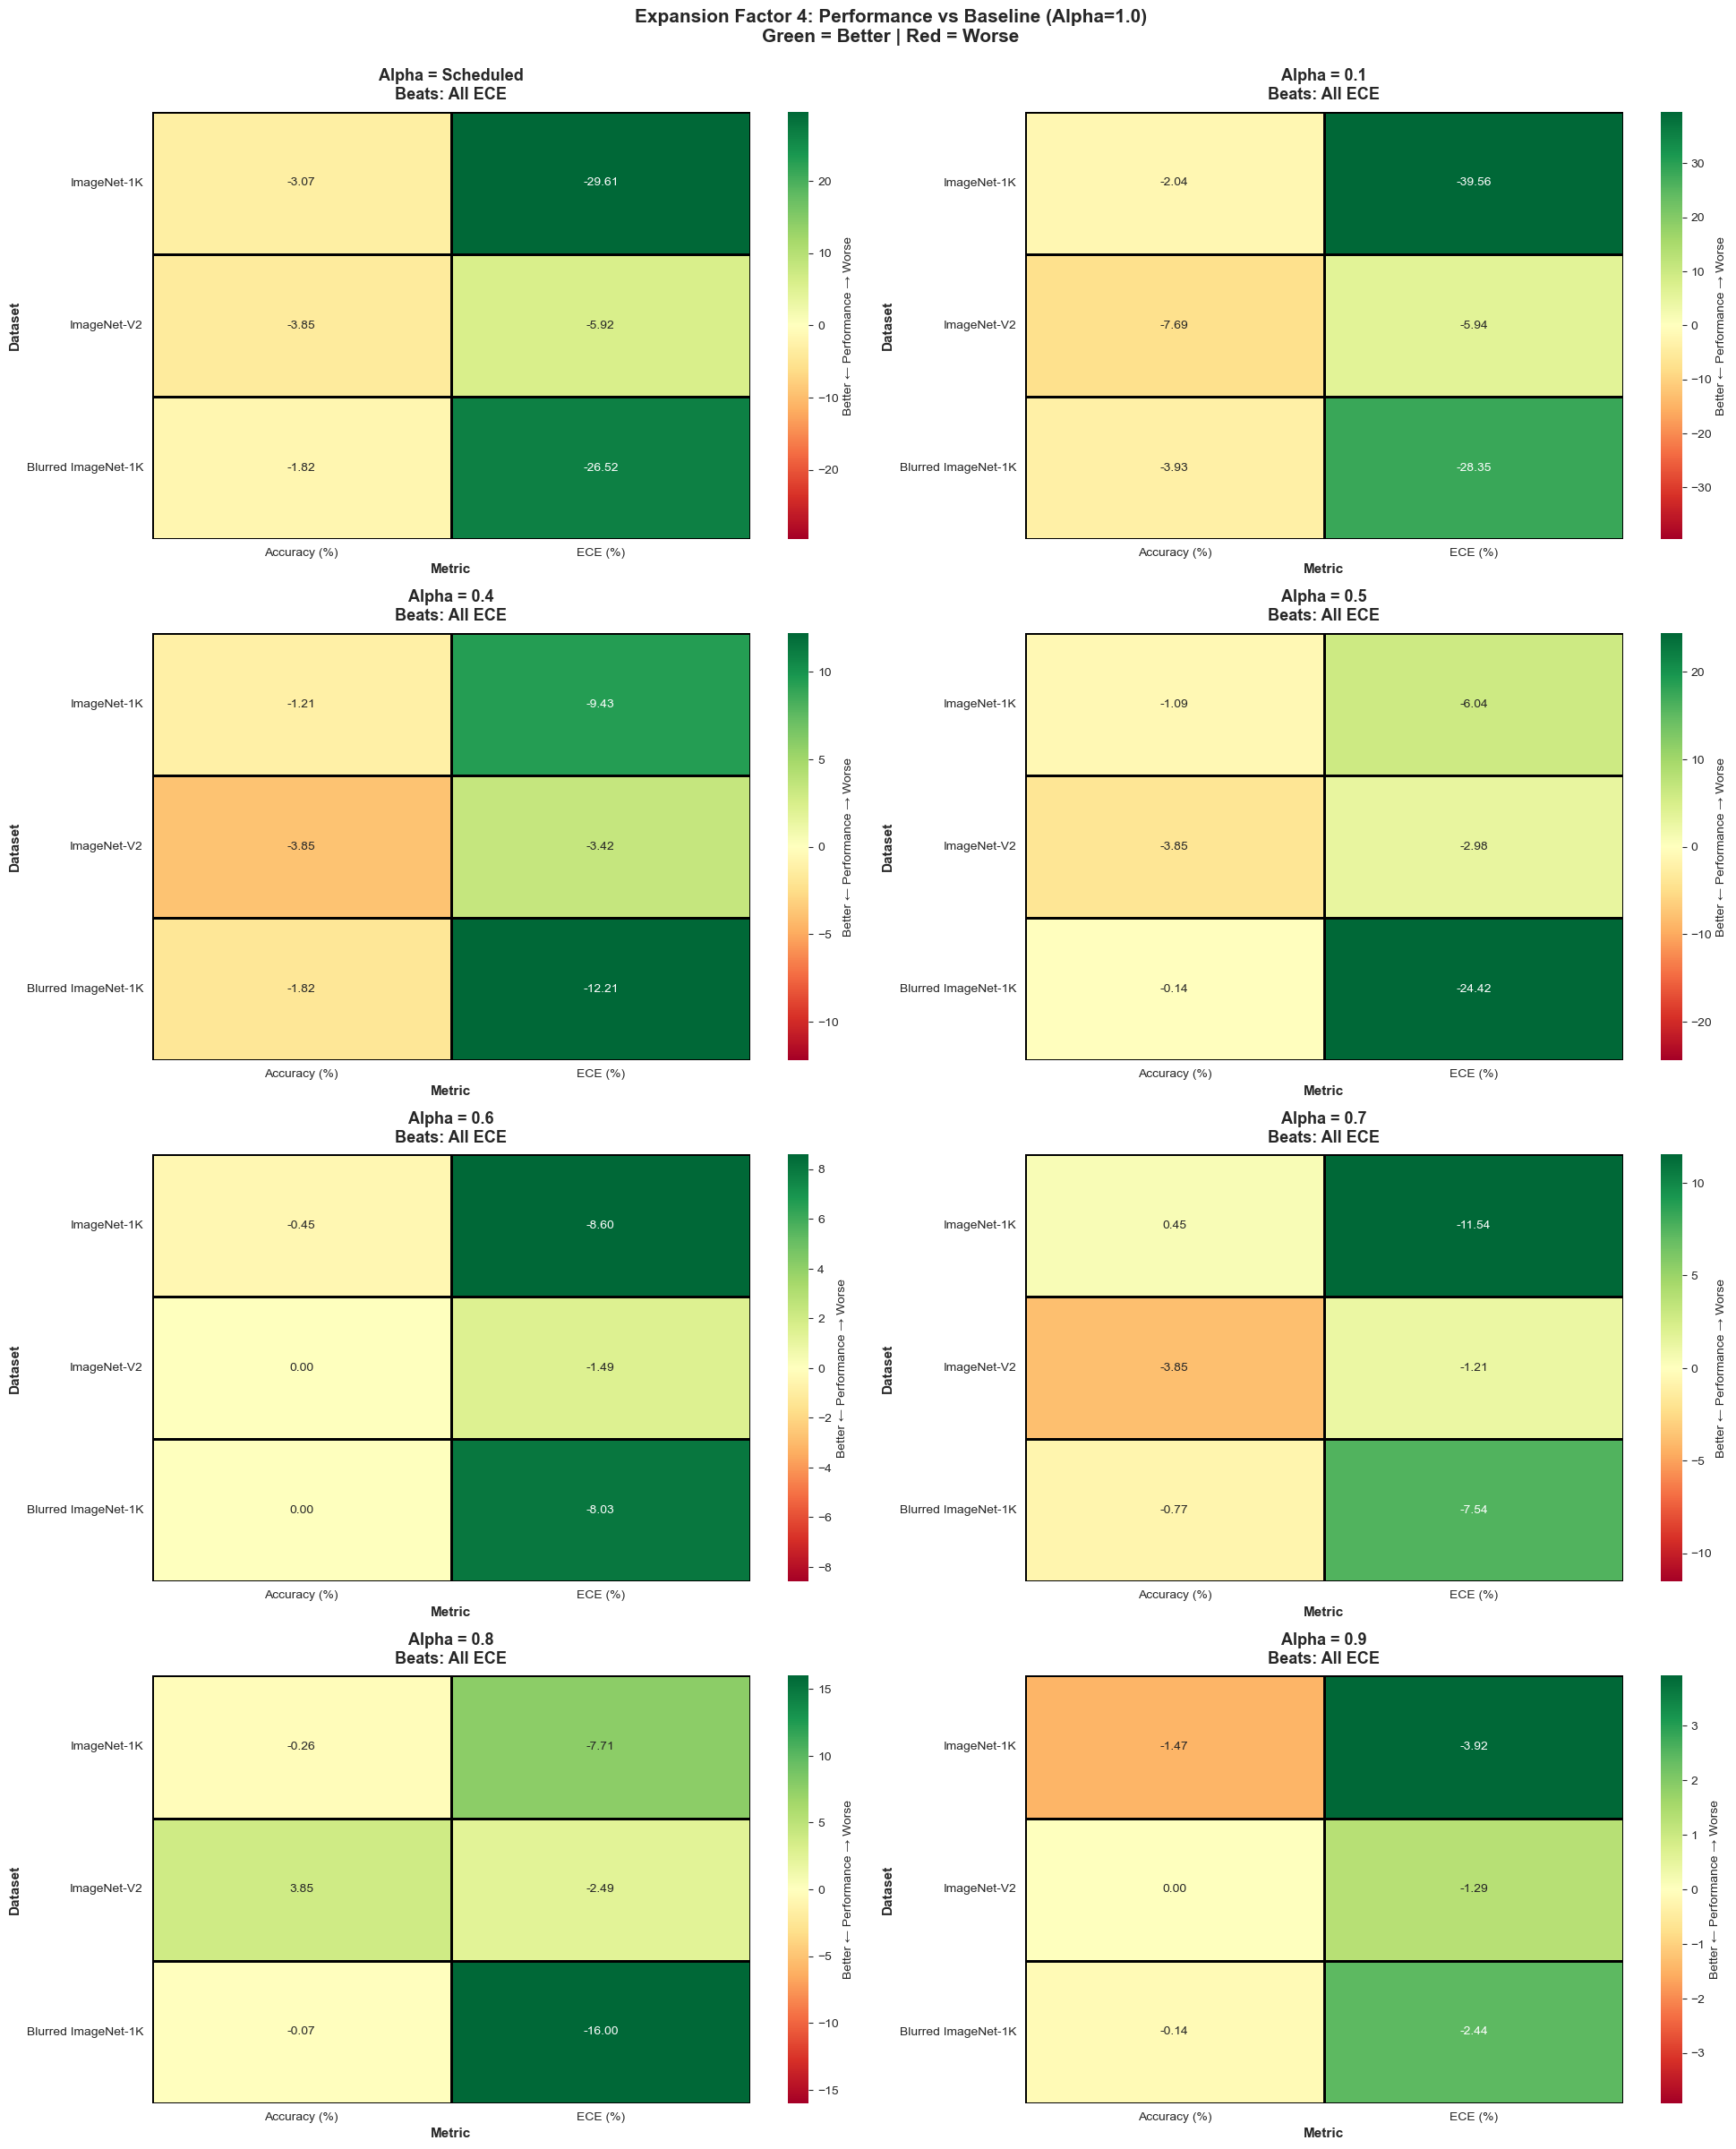

Note: For Accuracy, positive % = improvement. For ECE, negative % = improvement (lower is better).



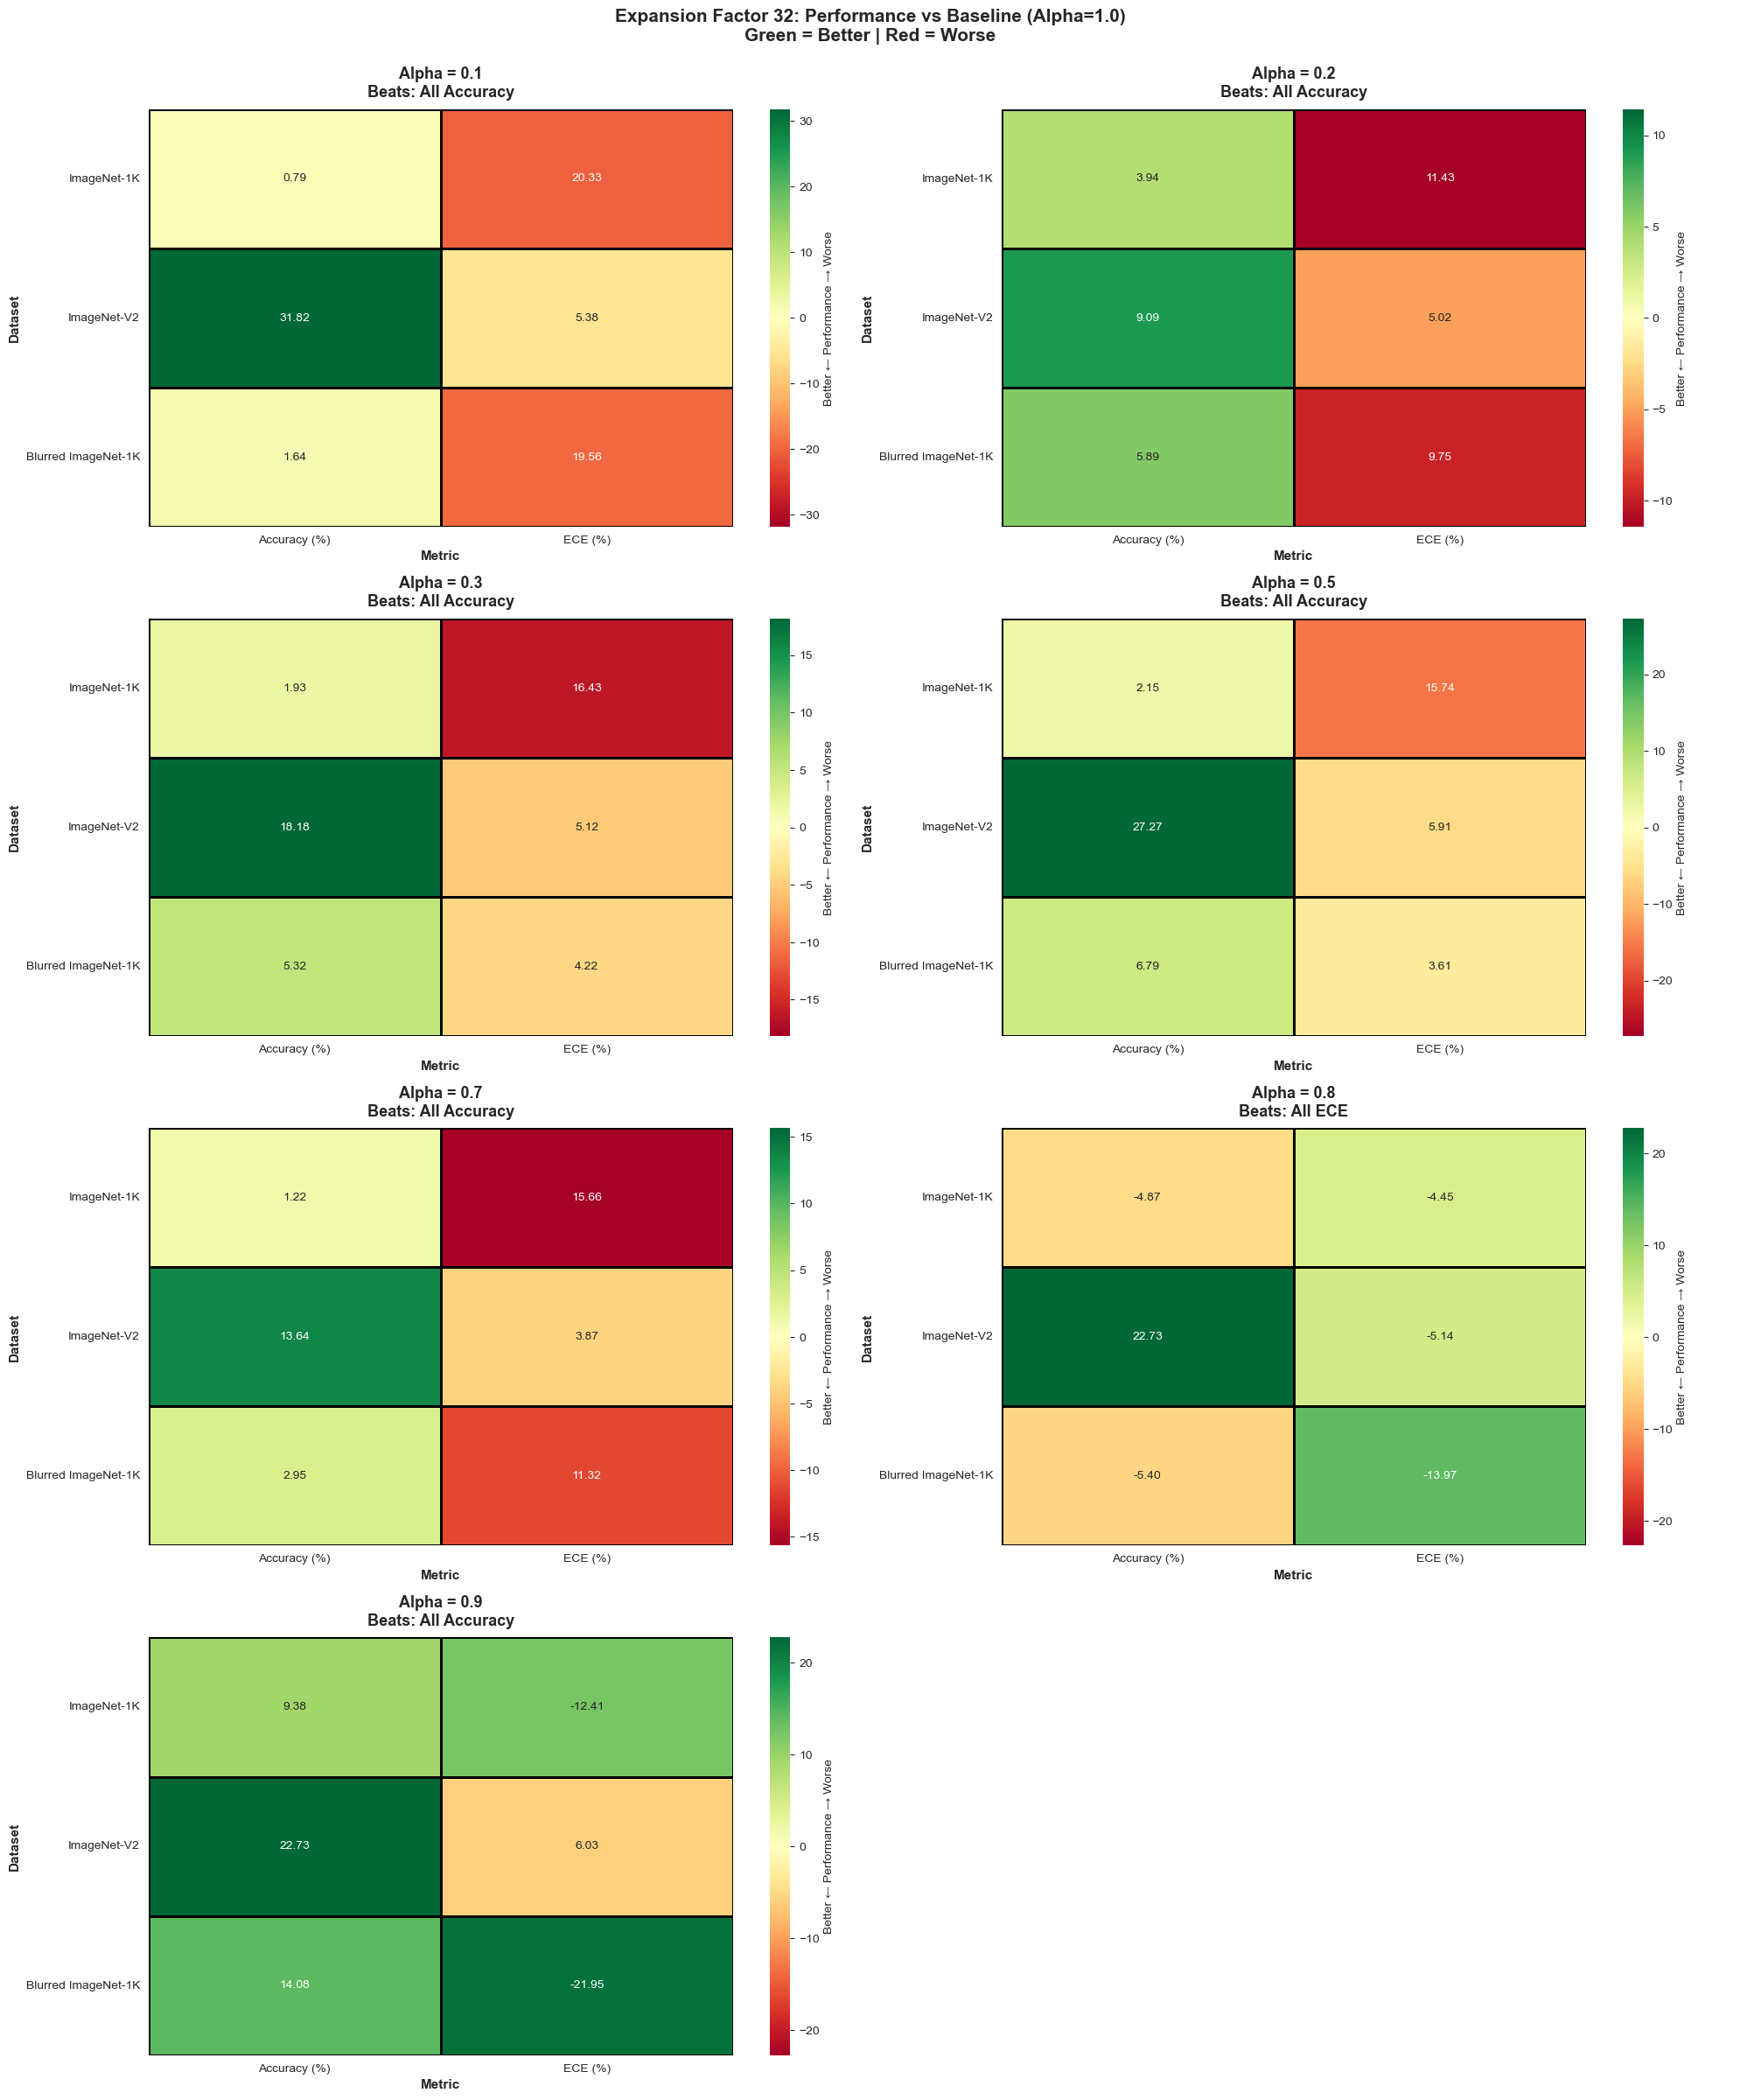

Note: For Accuracy, positive % = improvement. For ECE, negative % = improvement (lower is better).



In [28]:
# Create detailed heatmaps for each winning model showing % change from baseline
if all_winners:
    for exp in sorted(df_all_models['expansion'].unique()):
        exp_winners = [w for w in all_winners if w['expansion'] == exp]
        
        if exp_winners:
            # Calculate number of rows needed (2 models per row)
            n_models = len(exp_winners)
            n_cols = min(2, n_models)
            n_rows = (n_models + 1) // 2
            
            fig, axes = plt.subplots(n_rows, n_cols, figsize=(10*n_cols, 6*n_rows))
            if n_models == 1:
                axes = np.array([axes])
            axes = axes.flatten() if n_models > 1 else axes
            
            baseline_exp = df_baseline[df_baseline['expansion'] == exp].iloc[0]
            df_exp = df_all_models[df_all_models['expansion'] == exp].copy()
            
            for idx, winner_dict in enumerate(exp_winners):
                ax = axes[idx]
                
                # Get the winner data from the dataframe
                alpha_val = winner_dict['alpha']
                alpha_label = winner_dict['alpha_label']
                winner = df_exp[df_exp['alpha'] == alpha_val].iloc[0]
                
                # Create matrix of percentage changes (3 datasets × 2 metrics)
                # Rows: ImageNet-1K, ImageNet-V2, Blurred ImageNet-1K
                # Cols: Accuracy, ECE
                percent_matrix = []
                
                for dataset_acc, dataset_ece in zip(datasets, ece_datasets):
                    acc_change = ((winner[dataset_acc] - baseline_exp[dataset_acc]) / baseline_exp[dataset_acc]) * 100
                    ece_change = ((winner[dataset_ece] - baseline_exp[dataset_ece]) / baseline_exp[dataset_ece]) * 100
                    percent_matrix.append([acc_change, ece_change])
                
                # Convert to numpy array (3 rows × 2 cols)
                data_matrix = np.array(percent_matrix)
                
                # Create adjusted matrix for coloring
                # For accuracy (col 0): positive is good (green), negative is bad (red)
                # For ECE (col 1): negative is good (green), positive is bad (red)
                adjusted_matrix = data_matrix.copy()
                adjusted_matrix[:, 1] = -adjusted_matrix[:, 1]  # Flip ECE column
                
                # Determine color scale limits
                vmax = max(abs(adjusted_matrix.min()), abs(adjusted_matrix.max()))
                vmin = -vmax
                
                # Create heatmap
                sns.heatmap(adjusted_matrix, annot=data_matrix, fmt='.2f', 
                           cmap='RdYlGn', center=0, vmin=vmin, vmax=vmax,
                           cbar_kws={'label': 'Better ← Performance → Worse'},
                           yticklabels=titles, 
                           xticklabels=['Accuracy (%)', 'ECE (%)'],
                           linewidths=2, linecolor='black', ax=ax,
                           cbar=True)
                
                # Formatting
                criteria = []
                if winner_dict['beats_accuracy']:
                    criteria.append("All Accuracy")
                if winner_dict['beats_ece']:
                    criteria.append("All ECE")
                
                title_text = f"Alpha = {alpha_label}\nBeats: {' & '.join(criteria)}"
                ax.set_title(title_text, fontsize=13, fontweight='bold', pad=10)
                ax.set_xlabel('Metric', fontsize=11, fontweight='bold')
                ax.set_ylabel('Dataset', fontsize=11, fontweight='bold')
                
                # Rotate x-axis labels for better readability
                ax.set_xticklabels(ax.get_xticklabels(), rotation=0, ha='center')
                ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
                
            # Hide extra subplots if odd number of models
            if n_models % 2 == 1 and n_models > 1:
                axes[-1].axis('off')
            
            plt.suptitle(f'Expansion Factor {exp}: Performance vs Baseline (Alpha=1.0)\nGreen = Better | Red = Worse',
                        fontsize=15, fontweight='bold', y=0.998)
            plt.tight_layout()
            plt.show()
            
            print(f"Note: For Accuracy, positive % = improvement. For ECE, negative % = improvement (lower is better).")
            print()
else:
    print("No models to visualize.")